# Run the simulation

### Problems
TODO: The following code saves the same simulation, despite replenish_rate is set to different values other than 0.

In [ ]:
# Jupyter-compatible version of run.py
from model import OpenCoverModel
from mesa.batchrunner import batch_run
import pickle
import pandas as pd
from tqdm import tqdm

# === Simulation Parameters (replace argparse with manual assignment) ===
behavior = "my_behavior"  # options: "pure_levy", "truncated_levy", "composite_levy", "biased_composite", "my_behavior", "all"
landing_prob = 1.0
n_agents = 60
iterations = 5            # Number of repetitions per setting (each with a different seed)
steps = 2 * 60 * 60       # Total number of simulation steps
num_processes = 10        # Use None for all CPUs
replenish_rate = 0       # 0.05, 0.5, 2, 5, 13

# === Determine which behaviors to run ===
if behavior == "all":
    behaviors_to_run = ["pure_levy", "truncated_levy", "composite_levy", "biased_composite", "my_behavior"]
else:
    behaviors_to_run = [behavior]

# === Run simulations ===
for behavior in behaviors_to_run:
    print(f"\n=== Running behavior: {behavior} ===\n")

    # Batch parameters
    param_dict = {
        "n_agents": n_agents,
        "bee_behavior": behavior,
        "landing_prob": landing_prob,
        "seed": range(iterations),
        "replenish_rate": replenish_rate
    }

    results = batch_run(
        model_cls=OpenCoverModel,
        parameters=param_dict,
        iterations=1,
        max_steps=steps,
        number_processes=num_processes,
        data_collection_period=10,
        display_progress=True
    )

    # Save output
    df = pd.DataFrame(results)
    output_filename = f"batch_results_{behavior}_rr_{replenish_rate}.pkl"
    with open(output_filename, "wb") as f:
        pickle.dump(results, f)

    print(f"Simulation complete. Results saved to {output_filename}")



=== Running behavior: my_behavior ===



  0%|          | 0/5 [00:00<?, ?it/s]

Simulation complete. Results saved to batch_results_my_behavior_rr_13.pkl


# Animating average number of bee visits per column 

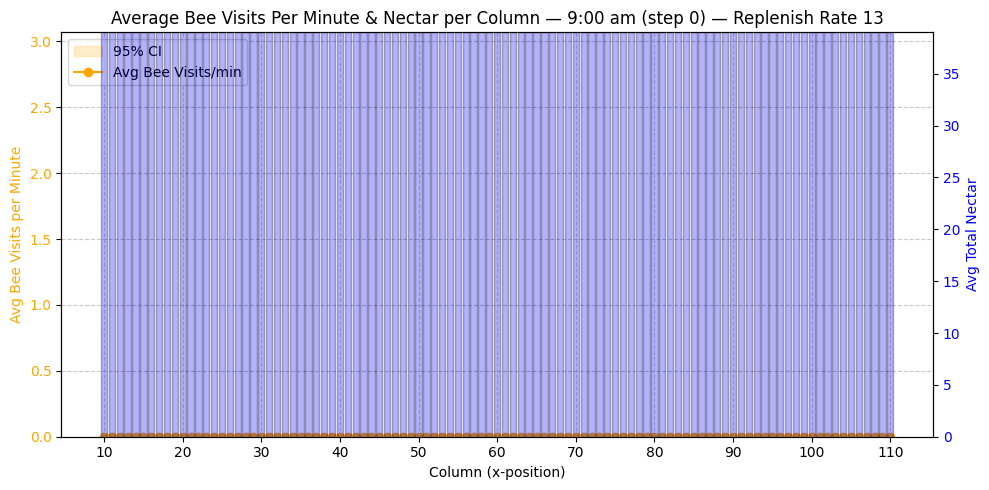

In [ ]:
%matplotlib inline
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import pandas as pd
import numpy as np

# === Load and preprocess data ===
sim_runs = pd.read_pickle(f"batch_results_my_behavior_rr_{replenish_rate}.pkl")
df = pd.DataFrame(sim_runs)

# Filter to Plant agents only
plant_df = df[df["Agent Type"] == "plant"].copy()
plant_df["Column"] = plant_df["Position"].apply(lambda pos: pos[0] if isinstance(pos, (list, tuple)) else None)
plant_df["Step"] = plant_df["Step"].astype(int)

# === Nectar Data ===
plant_df_nectar = plant_df.dropna(subset=["Plant nectar amount", "Column", "seed"]).copy()
plant_df_nectar = plant_df_nectar[plant_df_nectar["Step"] % 600 == 0]

per_run_totals = (
    plant_df_nectar.groupby(["Step", "Column", "seed"])["Plant nectar amount"]
    .sum()
    .reset_index(name="Total Nectar Per Run")
)

avg_total_nectar = (
    per_run_totals.groupby(["Step", "Column"])["Total Nectar Per Run"]
    .mean()
    .reset_index(name="Avg Total Nectar")
)

# === Bee Visit Data + CI ===
plant_df_visits = plant_df.dropna(subset=["Plant visit timestamp", "Column", "seed"]).copy()

def count_recent_visits(timestamps, current_step):
    if not isinstance(timestamps, (list, tuple)):
        return 0
    return sum((current_step - 300) < ts <= current_step for ts in timestamps)

timesteps = sorted(set(avg_total_nectar["Step"]).intersection(set(plant_df_visits["Step"].unique())))
timesteps = [t for t in timesteps if t % 600 == 0]

visit_results = []
for step in timesteps:
    step_df = plant_df_visits[plant_df_visits["Step"] == step].copy()
    step_df["Recent Visits"] = step_df["Plant visit timestamp"].apply(lambda ts: count_recent_visits(ts, step))
    
    per_run_column_visits = (
        step_df.groupby(["Column", "seed"])["Recent Visits"]
        .sum()
        .reset_index(name="TotalVisitsPerRun")
    )
    
    grouped = per_run_column_visits.groupby("Column")["TotalVisitsPerRun"]
    stats_df = grouped.agg(['mean', 'std', 'count']).reset_index()
    stats_df.rename(columns={"mean": "AvgVisitsAcrossRuns", "std": "StdDev", "count": "NumRuns"}, inplace=True)
    stats_df["AvgBeeVisitsPerMinute"] = stats_df["AvgVisitsAcrossRuns"] / 5
    stats_df["CI95"] = 1.96 * (stats_df["StdDev"] / np.sqrt(stats_df["NumRuns"])) / 5
    stats_df["Step"] = step
    
    visit_results.append(stats_df[["Step", "Column", "AvgBeeVisitsPerMinute", "CI95"]])

avg_visits_df = pd.concat(visit_results, ignore_index=True)

# === Pre-merge step data ===
merged_data = []
for step in timesteps:
    nectar_sub = avg_total_nectar[avg_total_nectar["Step"] == step]
    visits_sub = avg_visits_df[avg_visits_df["Step"] == step]
    merged = pd.merge(visits_sub, nectar_sub, on=["Step", "Column"], how="inner").sort_values("Column")
    merged_data.append(merged)

# === Compute fixed Y-axis limits ===
all_visits = avg_visits_df["AvgBeeVisitsPerMinute"]
all_ci = avg_visits_df["CI95"]
ymin_visits = max(0, (all_visits - all_ci).min())
ymax_visits = (all_visits + all_ci).max()

all_nectar = avg_total_nectar["Avg Total Nectar"]
ymin_nectar = 0
ymax_nectar = all_nectar.max()

# === Helper: step to time string ===
def step_to_time_str(step):
    hh = 9 + step // 3600
    mm = (step % 3600) // 60
    return f"{hh}:{mm:02d} am"

# === Setup animation ===
fig = plt.figure(figsize=(10, 5))

def update(frame_idx):
    fig.clf()
    ax1 = fig.add_subplot(111)
    ax2 = ax1.twinx()

    merged = merged_data[frame_idx]
    step = merged["Step"].iloc[0]
    time_str = step_to_time_str(step)

    # Nectar bars
    ax2.bar(
        merged["Column"], merged["Avg Total Nectar"],
        color="blue", edgecolor="black", alpha=0.3, zorder=1
    )
    ax2.set_ylabel("Avg Total Nectar", color="blue")
    ax2.tick_params(axis='y', labelcolor="blue")
    ax2.set_ylim(ymin_nectar, ymax_nectar)

    # Bee visits line and CI
    ax1.fill_between(
        merged["Column"],
        merged["AvgBeeVisitsPerMinute"] - merged["CI95"],
        merged["AvgBeeVisitsPerMinute"] + merged["CI95"],
        color="orange", alpha=0.2, label="95% CI", zorder=2
    )
    ax1.plot(
        merged["Column"], merged["AvgBeeVisitsPerMinute"],
        color="orange", marker='o', label="Avg Bee Visits/min", zorder=3
    )
    ax1.set_ylabel("Avg Bee Visits per Minute", color="orange")
    ax1.tick_params(axis='y', labelcolor="orange")
    ax1.set_ylim(ymin_visits, ymax_visits)
    ax1.set_xlabel("Column (x-position)")
    
    # X-ticks
    xticks = [x for x in merged["Column"].unique() if x % 10 == 0]
    ax1.set_xticks(xticks)

    # Title with formatted time and step
    ax1.set_title(f"Average Bee Visits Per Minute & Nectar per Column — {time_str} (step {step}) — Replenish Rate {replenish_rate}")

    # Legend
    handles, labels = ax1.get_legend_handles_labels()
    ax1.legend(handles, labels, loc="upper left", frameon=True)

    ax1.grid(True, linestyle='--', alpha=0.7)
    fig.tight_layout()

# === Run animation ===
anim = FuncAnimation(fig, update, frames=len(merged_data), interval=1000, repeat=False)
HTML(anim.to_jshtml())


In [4]:
# Saving the animation to HTML file
with open(f"bee_visitation_animation_rr_{replenish_rate}.html", "w") as f:
    f.write(anim.to_jshtml())

In [5]:
# For visualization in a web browser
import webbrowser
webbrowser.open(f"bee_visitation_animation_rr_{replenish_rate}.html")

True